# Redes Neuronales 2026

---

# Guía de ejercicios N.º 11: Clasificación de imágenes del conjunto Fashion-MNIST con PyTorch

Esta guía continúa con el hilo conceptual utilizado en la guía de *Autoencoder*, pero ahora la tarea es **clasificación supervisada**.

En el *autoencoder* la idea era reproducir la imagen de entrada luego de realizar una representación en el **espacio latente**:

$$
x \longrightarrow \hat{x}.
$$

Ahora queremos aprender:

$$
x \longrightarrow y,
$$

donde $y$ es la **clase correcta** de la imagen.

En este caso, la red no reconstruirá las imágenes. En cambio, producirá **10 logits**, uno por cada clase, y utilizaremos las etiquetas de Fashion-MNIST como objetivos.

> **Observación:** *train* se utiliza para actualizar parámetros, *validation* para comparar configuraciones y *test* se reserva para la evaluación final.

## Ejercicio 1) Preparar el entorno

### 1.1) Importar librerías

Usaremos las mismas herramientas básicas que en la guía anterior: PyTorch, `torchvision`, `DataLoader` y Matplotlib.

In [ ]:
import random

import matplotlib.pyplot as plt
import numpy as np
import torch

from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

### 1.2) Reproducibilidad y dispositivo

Fijamos semillas y elegimos automáticamente GPU si está disponible.

In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.14.1+cpu
Dispositivo: cpu


## Ejercicio 2) Cargar y preparar Fashion-MNIST

### 2.1) Transformación

En clasificación no necesitamos que la salida de la red tenga el mismo rango que los píxeles de entrada. Por eso podemos reescalar las imágenes al intervalo `[-1,1]`.

Primero `ToTensor()` lleva los píxeles a `[0,1]`. Luego:

$$
x_{\mathrm{norm}}
=
\frac{x-0.5}{0.5}.
$$

Así obtenemos:

$$
x_{\mathrm{norm}}\in[-1,1].
$$

**Observación:** esta transformación **reescala** los píxeles, pero **no centra** los datos. Como la mayoría de los píxeles de Fashion-MNIST corresponden al fondo (negro, $x=0$, que se transforma en $x_{\mathrm{norm}}=-1$), la media de los píxeles normalizados es aproximadamente $-0.43$, y no cero. Lo importante aquí es que las entradas tomen valores de orden 1, de modo que las preactivaciones de la primera capa tengan una escala razonable.

Una alternativa es **estandarizar** las entradas utilizando la media y el desvío estándar de los píxeles de Fashion-MNIST ($\mu\approx0.286$, $\sigma\approx0.353$):

```python
transforms.Normalize((0.286,), (0.353,))
```

con lo cual las entradas quedan, en promedio, con media cero y varianza unitaria.

Esta elección es distinta de la del *autoencoder*: allí utilizábamos `[0,1]` porque la salida `Sigmoid` debía reconstruir los valores de los píxeles en `[0,1]`.

In [ ]:
transform = transforms.Compose([transforms.ToTensor(),
                               transforms.Normalize((0.5,), (0.5,))
])
#transform = transforms.Normalize((0.286,),(0.353,))


### 2.2) *Train*, *validation* y *test*

Usaremos la misma metodología que en la guía del *autoencoder*:

- 50.000 imágenes para *train*;
- 10.000 imágenes para *validation*;
- 10.000 imágenes oficiales para *test*.

No visualizaremos nuevamente el *dataset* (ya lo hicimos en la guía de práctico del *Autoencoder*). Nos concentraremos directamente en la **tarea de clasificación**.

In [ ]:
full_train_set = datasets.FashionMNIST(root='data',
                                       train=True,
                                       download=True,
                                       transform=transform)
test_set = datasets.FashionMNIST(root='data',
                                       train=False,
                                       download=True,
                                       transform=transform)

split_generator = torch.Generator().manual_seed(SEED)

train_set, valid_set = random_split(full_train_set,
                                    [50000, 10000],
                                    generator=split_generator)
print("------------------")
print("Train:", len(train_set))
print("Validation:", len(valid_set))
print("Test:", len(test_set))

100%|██████████| 26.4M/26.4M [00:01<00:00, 15.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 235kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.37MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.36MB/s]

------------------
Train: 50000
Validation: 10000
Test: 10000


### 2.3) Nombres de las clases

Fashion-MNIST codifica las categorías con **números enteros** de `0` a `9`.

El siguiente **diccionario** sólo se utilizará para traducir las **etiquetas numéricas** a **nombres legibles** cuando analicemos las predicciones.

In [ ]:
#clases = datasets.FashionMNIST
#print(clases)
class_names = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot",
}

## Ejercicio 3) Crear los `DataLoader`s

Como en el *autoencoder*, el entrenamiento se realiza **mini-batch por mini-batch**.

Usaremos *mini-batches* de 100 imágenes:

```text
images.shape = (B, 1, 28, 28)
labels.shape = (B,)
```

`train_loader` usa `shuffle=True`. *Validation* y *test* usan `shuffle=False`.

In [ ]:
BATCH_SIZE = 100

train_loader = DataLoader(train_set,
                          batch_size=BATCH_SIZE,
                          shuffle=True)

valid_loader = DataLoader(valid_set,
                          batch_size=BATCH_SIZE,
                          shuffle=False)

test_loader = DataLoader(test_set,
                          batch_size=BATCH_SIZE,
                          shuffle=False)


images, labels = next(iter(train_loader))

print("images.shape:", images.shape)
print("labels.shape:", labels.shape)

images.shape: torch.Size([100, 1, 28, 28])
labels.shape: torch.Size([100])


## Ejercicio 4) Comprender la tarea de clasificación

En un *autoencoder*:

$$
x\longrightarrow\hat{x}.
$$

En **clasificación supervisada**:

$$
x\longrightarrow y.
$$

Para una imagen, la red producirá un vector de 10 valores:

$$
\mathbb{z}
=
[z_0,z_1,\ldots,z_9]^T,
$$
vector de todos ceros salvo en la posicion de la clase predicha

donde cada $z_k$ es un *logit* para la clase $k$.

Los logits:

- son números reales;
- no son probabilidades;
- no tienen que estar entre 0 y 1;
- no tienen que sumar 1.

Conceptualmente, *softmax* transforma los *logits* en **probabilidades**:

$$
p_k
=
\frac{e^{z_k}}
{\sum_{j=0}^{9}e^{z_j}}.
$$

La clase predicha es la de mayor *logit*, equivalentemente la de **mayor probabilidad**:

$$
\hat{y}
=
\operatorname*{arg\,max}_k z_k.
$$

A diferencia del *autoencoder*, aquí **sí necesitamos las etiquetas** (por etiquetas nos referimos a los números enteros entre 0 y 9 que denotan cada clase, no nos referimos a los nombres de las clases) porque ellas indican cuál de las 10 clases es la correcta.

## Ejercicio 5) Definir la red de clasificación

Usaremos una MLP **completamente conectada**:

$$
784
\longrightarrow
128
\longrightarrow
64
\longrightarrow
10.
$$

Para un *mini-batch*:

$$
(B,1,28,28)
\longrightarrow
(B,784)
\longrightarrow
(B,128)
\longrightarrow
(B,64)
\longrightarrow
(B,10).
$$

La última capa produce 10 *logits*. No agregamos `Softmax` al modelo porque `CrossEntropyLoss` trabaja directamente con *logits*.

Incluiremos `Dropout(p=0.2)` después de las activaciones ocultas.

In [ ]:
class FashionMLP(nn.Module):
    def __init__(self, p_dropout=0.2):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(28*28, 128),
            nn.ReLU(),
            nn.Dropout(p_dropout),   #evita el overfitting

            nn.Linear(128,64),
            nn.ReLU(),
            nn.Dropout(p_dropout),

            nn.Linear(64,10)
        )

    def forward(self, x):
        return self.network(x)


### 5.1) Comprobar dimensiones

Antes de entrenar, verificamos el *forward pass*.

Para $B$ imágenes y 10 clases esperamos:

$$
(B,1,28,28)
\longrightarrow
(B,10).
$$

In [ ]:
DROPOUT_P = 0.2
torch.manual_seed(SEED)

model_example = FashionMLP(DROPOUT_P)

with torch.no_grad():
    logit = model_example(images)

print("Entrada", images.shape)
print("Logits", logit.shape)

n_params = sum(
    p.numel()
    for p in model_example.parameters()
    if p.requires_grad
)
print(f"Parametros entrenables {n_params:,}")

Entrada torch.Size([100, 1, 28, 28])
Logits torch.Size([100, 10])
Parametros entrenables 109,386


## Ejercicio 6) Función de pérdida

Para **clasificación multiclase** utilizaremos la función de pérdida denominada **Entropía Cruzada** ($L$) (`CrossEntropyLoss`).

Para un ejemplo cuya clase verdadera es $y$, conceptualmente:

$$
L
=
-\log(p_y),
$$

donde $p_y$ es la probabilidad asignada por *softmax* a la **clase correcta**.

PyTorch implementa de manera numéricamente estable la combinación:

```text
logits → log-softmax → negative log-likelihood
```

Por eso:

- la red debe devolver **logits**;
- no aplicamos `Softmax` antes de la pérdida;
- las etiquetas son enteros entre `0` y `9`, no vectores *one-hot*.

In [ ]:
loss_fn = nn.CrossEntropyLoss()

## Ejercicio 7) Elegir el optimizador

Usaremos las mismas dos opciones que en la guía del *autoencoder*:

- SGD: `lr=0.01`;
- Adam: `lr=0.001`.

Comenzaremos con *Adam* y luego compararemos ambas configuraciones utilizando *validation*.

In [ ]:
OPTIMIZER_NAME = 'Adam'

SGD_LR = 0.01
ADAM_LR = 0.001

## Ejercicio 8) Implementar una época de entrenamiento

El `DataLoader` entrega *mini-batches*:

```python
for images, labels in data_loader:
```

Para cada *mini-batch*:

1. activar modo **entrenamiento**;
2. mover imágenes y etiquetas al dispositivo;
3. borrar gradientes anteriores;
4. hacer *forward*;
5. calcular *Cross-Entropy Loss*;
6. hacer *backpropagation*;
7. actualizar parámetros.

Como en el *Autoencoder*, `optimizer.step()` es la instrucción que modifica los pesos.

In [ ]:
def train_one_epoch(model, data_loader, loss_fn, optimizer, device):
    model.train()
    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()  #que arranque los gradientes en cero

        logits = model(images)
        loss = loss_fn(logits, labels)

        loss.backward()
        optimizer.step()

## Ejercicio 9) Implementar la evaluación

Durante evaluación:

- usamos `model.eval()`;
- desactivamos el cálculo de gradientes;
- no actualizamos parámetros;
- calculamos tanto pérdida (*loss*) como *accuracy*.

Para cada *mini-batch*:

```python
predictions = logits.argmax(dim=1)
```

selecciona la clase de mayor *logit* para cada imagen.

In [ ]:
@torch.no_grad()

def evaluate(model, data_loader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in data_loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)
        loss = loss_fn(logits, labels)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = logits.argmax(dim=1)
        total_correct += (predictions == labels).sum().item()

        total_examples += batch_size

    mean_loss = total_loss / total_examples
    accuracy = total_correct / total_examples

    return mean_loss, accuracy

## Ejercicio 10) Crear el modelo y el optimizador

Ahora creamos una instancia nueva del modelo y asociamos el optimizador seleccionado a sus parámetros.

In [ ]:
torch.manual_seed(SEED)

model = FashionMLP(p_dropout=DROPOUT_P ).to(device)

if OPTIMIZER_NAME == "SGD":
    optimizer = torch.optim.SGD(model.parameters(), lr=SGD_LR)

elif OPTIMIZER_NAME == "Adam":
    optimizer = torch.optim.Adam(model.parameters(), lr=ADAM_LR)

else:
    raise ValueError("OPTIMIZER_NAME debe ser 'SGD' o 'Adam'.")

print("Optimizador:", OPTIMIZER_NAME)
print("Dropout p:", DROPOUT_P)


Optimizador: Adam
Dropout p: 0.2


### 10.1) Predicciones antes del entrenamiento

Antes del entrenamiento, los pesos son aleatorios. Por eso no esperamos predicciones útiles.

Usaremos *validation*, NO *test*, para observar algunas predicciones iniciales.

Esta sección cumple el mismo rol conceptual que las reconstrucciones antes de  entrenar el *autoencoder*: mostrar que la arquitectura por sí sola no sabe cómo clasificar imágenes correctamente todavía.

In [ ]:
@torch.no_grad()
def show_untrained_predictions(model, data_loader, device, n=8):
    model.eval()

    images, labels = next(iter(data_loader))
    images = images[:n]
    labels = labels[:n]

    logits = model(images.to(device))
    predictions = logits.argmax(dim=1).cpu()

    print("Etiqueta real --> predicción inicial")
    for true_label, pred_label in zip(labels, predictions):
        print(
            f"{class_names[true_label.item()]:12s}"
            f"-->{class_names[pred_label.item()]}"
        )


show_untrained_predictions(model, valid_loader, device)

Etiqueta real --> predicción inicial
Shirt       -->Coat
Trouser     -->Ankle boot
Bag         -->Shirt
Sneaker     -->Coat
Sandal      -->Ankle boot
Trouser     -->Coat
Sneaker     -->Coat
Trouser     -->Coat


## Ejercicio 11) Entrenar el modelo

En cada época:

```text
actualizar parámetros usando train
        ↓
evaluar train con los pesos finales
        ↓
evaluar validation con los mismos pesos
```

Así las métricas de *train* y *validation* corresponden exactamente al mismo estado del modelo.

Como en la guía del *autoencoder*, `train_one_epoch()` sólo actualiza pesos; las métricas se calculan después con `evaluate()`.

In [ ]:
EPOCHS = 20

history = {
    "train_loss": [],
    "valid_loss": [],
    "train_acc": [],
    "valid_acc": []
}

for epoch in range(1, EPOCHS + 1):
    train_one_epoch(model,
                    train_loader,
                    loss_fn,
                    optimizer,
                    device)

    train_loss , train_acc = evaluate(model,
                                      train_loader,
                                      loss_fn,
                                      device)

    valid_loss, valid_acc = evaluate(model,
                                      valid_loader,
                                      loss_fn,
                                      device)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["valid_loss"].append(valid_loss)
    history["valid_acc"].append(valid_acc)

    #print(f"Época {epoch:02d}/{EPOCHS}")
   # print(f"train_loss ={train_loss:9.4f}, acc={train_acc:.3f}")
    #print(f"valid_loss ={valid_loss:9.4f}, acc={valid_acc:.3f}")

## Ejercicio 12) Graficar las métricas

En clasificación observaremos dos cantidades:

- `CrossEntropyLoss`;
- `accuracy`.

La **Pérdida** o **Error** (`CrossEntropyLoss` en este caso) es la función a partir de la cual se calculan los gradientes durante el proceso de entrenamiento de la red neuronal. La *accuracy* (exactitud) es una métrica interpretable de aciertos en el proceso de clasificación de las imágenes por parte de la red.

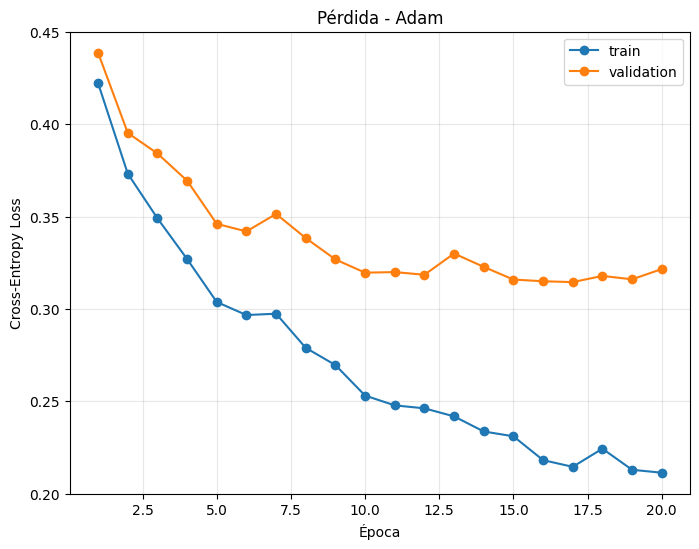

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(8,6))
plt.plot(epochs, history["train_loss"], marker="o", label="train")
plt.plot(epochs, history["valid_loss"], marker="o", label="validation")
plt.xlabel("Época")
plt.ylabel("Cross-Entropy Loss")
plt.title(f"Pérdida - {OPTIMIZER_NAME}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#probar modificando el drop_out

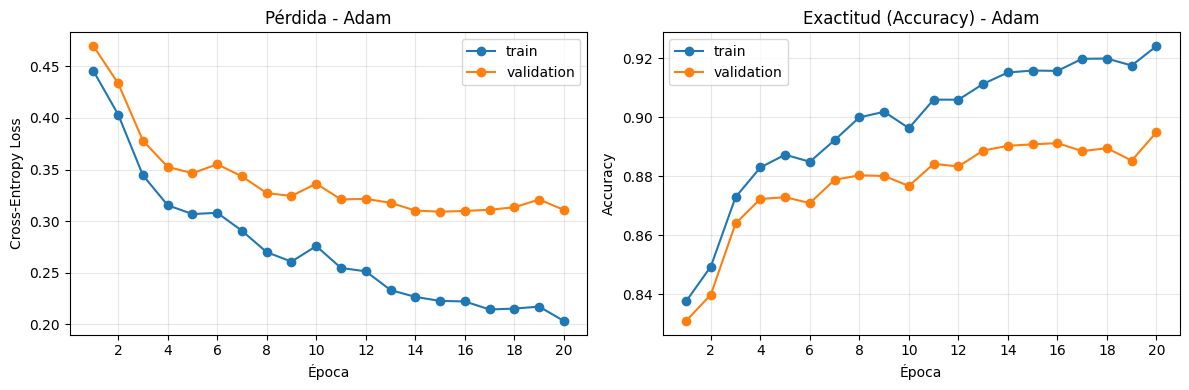

In [ ]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico de pérdida (Loss)
ax_loss.plot(epochs, history["train_loss"], marker="o", label="train")
ax_loss.plot(epochs, history["valid_loss"], marker="o", label="validation")


# Gráfico de accuracy (Corregido: agregado .plot)
ax_acc.plot(epochs, history["train_acc"], marker="o", label="train")
ax_acc.plot(epochs, history["valid_acc"], marker="o", label="validation")

ax_loss.set_xlabel("Época")
ax_loss.set_ylabel("Cross-Entropy Loss")
ax_loss.set_title(f"Pérdida - {OPTIMIZER_NAME}")
ax_loss.legend()
ax_loss.grid(alpha=0.3)
ax_loss.set_xticks(range(2, 21, 2))
# Configuración del eje de exactitud
ax_acc.set_xlabel("Época")
ax_acc.set_ylabel("Accuracy")
ax_acc.set_title(f"Exactitud (Accuracy) - {OPTIMIZER_NAME}")
ax_acc.legend()
ax_acc.grid(alpha=0.3)
ax_acc.set_xticks(range(2, 21, 2))

plt.tight_layout()
plt.show()

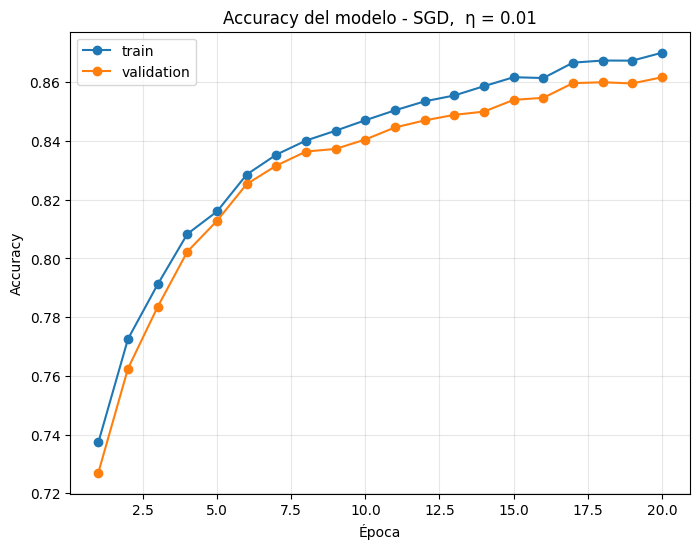

In [ ]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(8,6))
plt.plot(epochs, history["train_acc"], marker="o", label="train")
plt.plot(epochs, history["valid_acc"], marker="o", label="validation")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.title(f"Accuracy - {OPTIMIZER_NAME},  η = {SGD_LR}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Ejercicio 13) Comparar *SGD* y *Adam* utilizando *validation*

Hasta este punto no necesitamos utilizar *test*.

En los Ejercicios 10, 11 y 12 entrenamos el modelo paso a paso. Para comparar configuraciones conviene **encapsular todo el experimento en una función**:

```text
fijar semillas → crear modelo → crear optimizador → entrenar → registrar métricas
```

Esto tiene dos ventajas:

- cada corrida devuelve su propio `history`, de modo que los resultados de una configuración **no sobrescriben** los de otra;
- como las semillas se fijan **dentro** de la función, cada corrida es **reproducible**: la inicialización de los pesos, el orden de los *mini-batches* y las máscaras de *Dropout* quedan determinados por `seed`, independientemente de qué celdas se hayan ejecutado antes.

Mantener constantes:
- arquitectura;
- dropout;
- batch size;
- número de épocas.

Comparar principalmente:

- `valid_loss` y `valid_acc` **de la última época**;
- velocidad de convergencia;
- estabilidad de las curvas.

**Elegir la configuración utilizando sólo *validation*.**

### 13.1) Función para ejecutar un experimento completo

`make_optimizer()` crea el optimizador a partir de su nombre y `run_experiment()` ejecuta un entrenamiento completo, igual al de los Ejercicios 10 y 11, y devuelve el modelo entrenado y su `history`.

Para evaluar *train* usamos un `DataLoader` **sin** `shuffle`: el orden no afecta a la evaluación y así no consumimos números aleatorios del generador que determina el orden de los *mini-batches* de entrenamiento.

In [ ]:
torch.manual_seed(SEED)
EPOCHS = 20

def make_optimizer(name, params):
    if name == "SGD" :
        return torch.optim.SGD(params, lr=SGD_LR)
    elif name == "Adam":
        return torch.optim.Adam(params, lr=ADAM_LR)
    else:
        raise ValueError("OPTIMIZER_NAME debe ser 'SGD' o 'Adam'.")

def run_experiment(optimizer_name, seed=SEED, epochs=EPOCHS, p_dropout=DROPOUT_P, verbose=False):
    #si no se indican usamos los valores globales actuales

    torch.manual_seed(seed)
    loader_generator = torch.Generator().manual_seed(seed)

    train_loader_exp = DataLoader(train_set,
                                  batch_size=BATCH_SIZE,
                                  shuffle=True,
                                  generator=loader_generator)

    model= FashionMLP(p_dropout=p_dropout).to(device)
    optimizer =  make_optimizer(optimizer_name, model.parameters())

    history = {
        "train_loss": [],
        "valid_loss": [],
        "train_acc": [],
        "valid_acc": []
    }

    for epoch in range(1, EPOCHS + 1):
        train_one_epoch(model,
                        train_loader,
                        loss_fn,
                        optimizer,
                        device)

        train_loss , train_acc = evaluate(model,
                                        train_loader,
                                        loss_fn,
                                        device)

        valid_loss, valid_acc = evaluate(model,
                                        valid_loader,
                                        loss_fn,
                                        device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["valid_loss"].append(valid_loss)
        history["valid_acc"].append(valid_acc)

    return model, history

### 13.2) Entrenar ambas configuraciones

Entrenamos SGD y Adam con la **misma semilla** y los mismos hiperparámetros, salvo el optimizador y su *learning rate*. Guardamos cada resultado en el diccionario `results`.

In [ ]:
results = {}
results["SGD"]  = run_experiment(optimizer_name="SGD", verbose=True)
results["Adam"] = run_experiment(optimizer_name="Adam", verbose=True)

print("Métricas de validación en la última época:")
print(f"{'Optimizador':12s} {'lr':>7s} {'valid loss':>11s} {'valid acc':>10s}")
for name, (_, hist) in results.items():
    lr = SGD_LR if name == "SGD" else ADAM_LR
    print(f"{name:12s} {lr:7.3g}")
    print(f"{hist['valid_loss'][-1]:11.4f} {hist['valid_acc'][-1]:10.3f}")

Métricas de validación en la última época:
Optimizador       lr  valid loss  valid acc
SGD             0.01
     0.3793      0.864
Adam           0.001
     0.3109      0.895


### 13.3) Comparar las curvas

Graficamos ambas configuraciones juntas: línea continua para *validation* y línea discontinua para *train*.

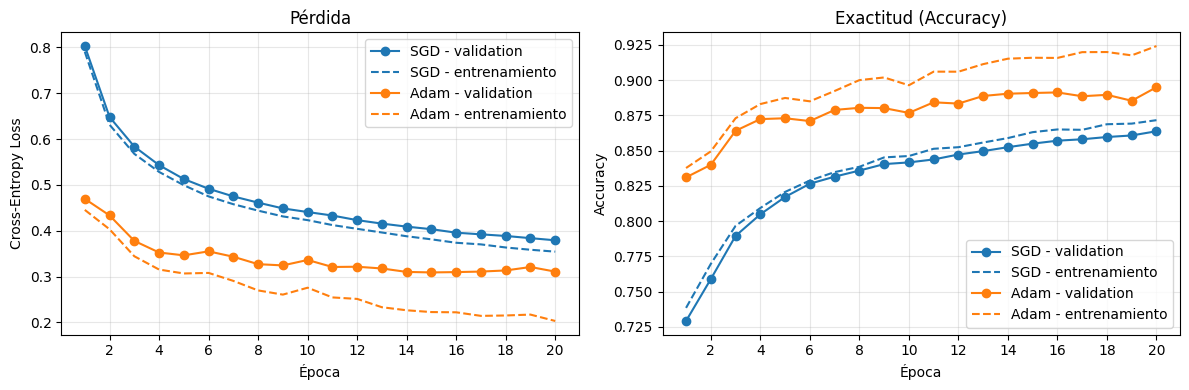

In [ ]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))

for name, (_, hist) in results.items():
    epoch_range = range(1, len(hist["valid_loss"]) + 1)

    # Gráfico de pérdida (Loss)
    line, = ax_loss.plot(epoch_range, hist["valid_loss"], marker="o", label=f"{name} - validation")
    ax_loss.plot(epoch_range, hist["train_loss"], linestyle="--", color=line.get_color(), label=f"{name} - entrenamiento")

    # Gráfico de precisión (Accuracy)
    line_acc, = ax_acc.plot(epoch_range, hist["valid_acc"], marker="o", label=f"{name} - validation")
    ax_acc.plot(epoch_range, hist["train_acc"], linestyle="--", color=line_acc.get_color(), label=f"{name} - entrenamiento")

# Configuración del eje de pérdida
ax_loss.set_xlabel("Época")
ax_loss.set_ylabel("Cross-Entropy Loss")
ax_loss.set_title("Pérdida")
ax_loss.legend()
ax_loss.grid(alpha=0.3)
ax_loss.set_xticks(range(2, 21, 2))
# Configuración del eje de exactitud
ax_acc.set_xlabel("Época")
ax_acc.set_ylabel("Accuracy")
ax_acc.set_title("Exactitud (Accuracy)")
ax_acc.legend()
ax_acc.grid(alpha=0.3)
ax_acc.set_xticks(range(2, 21, 2))

plt.tight_layout()
plt.show()

### 13.4) (Opcional) Variabilidad entre semillas

Una única corrida por configuración no permite saber si una diferencia en *validation* es **real** o es producto del azar (inicialización, orden de los *mini-batches*, *Dropout*).

Repitiendo cada configuración con varias semillas podemos estimar la media y el desvío estándar de las métricas, y preguntarnos: **¿es la diferencia entre SGD y Adam mayor que la variabilidad entre corridas?**

> Esta celda entrena $2\times3=6$ modelos, por lo que puede demorar varios minutos.

In [ ]:
SEEDS = [SEED, SEED + 1, SEED + 2]

for name in ["SGD","Adam"]:
        histories = [run_experiment(name, seed=s)[1] for s  in SEEDS]

        vl = np.array([h["valid_loss"][-1] for h in histories])
        va = np.array([h["valid_acc"][-1] for h in histories])

        print(f"{name:5s} | valid loss = {vl.mean():.4f} ± {vl.std(ddof=1):.4f}")
        print(f"valid accuracy = {va.mean():.4f} ± {va.std(ddof=1):.4f}")

SGD   | valid loss = 0.3454 ± 0.0044
valid accuracy = 0.8760  ± 0.0026
Adam  | valid loss = 0.3773 ± 0.0130
valid accuracy = 0.8721  ± 0.0044


### 13.5) Fijar la configuración seleccionada

Elegir el optimizador **a partir de los resultados sobre *validation*** y recuperar el modelo entrenado y su `history` correspondientes.

A partir de aquí, `model` es el **modelo final**: el que se evaluará sobre *test* en los ejercicios siguientes. Sus curvas de entrenamiento son las que corresponde mostrar en el informe.

In [ ]:
SELECTED_OPTIMIZER = "Adam"

model, history = results[SELECTED_OPTIMIZER]

print("Configuración seleccionada:", SELECTED_OPTIMIZER)
print(f"Valid loss (última época): {history['valid_loss'][-1]:.4f}")
print(f"Valid acc (última época): {history['valid_acc'][-1]:.4f}")

Configuración seleccionada: Adam
Valid loss (última época): 0.3109
Valid acc (última época): 0.8949


## Ejercicio 14) Evaluar la configuración seleccionada sobre *test*

La metodología es la misma que en el *autoencoder*:

$$
\text{train}
\longrightarrow
\text{aprendizaje de parámetros},
$$

$$
\text{validation}
\longrightarrow
\text{comparación de configuraciones},
$$

$$
\text{test}
\longrightarrow
\text{evaluación final}.
$$

Recién ahora medimos el modelo sobre las 10.000 imágenes oficiales de *test*.

In [ ]:
test_loss, test_acc = evaluate(model,
                               test_loader,
                               loss_fn,
                               device)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.3f}")

Test loss: 0.3362
Test accuracy: 0.887


## Ejercicio 15) Visualizar errores de clasificación sobre *test*

Ahora sí podemos observar imágenes concretas del conjunto de *test* porque la configuración ya fue seleccionada.

Las imágenes **bien** clasificadas aportan poca información. Mostraremos en cambio imágenes **mal clasificadas**: observarlas ayuda a entender qué tipo de errores comete la red y si resultan razonables desde el punto de vista visual.

Como las imágenes están normalizadas a `[-1,1]`, para visualizarlas recuperamos el intervalo `[0,1]` invirtiendo la transformación: $x = 0.5\,x_{\mathrm{norm}} + 0.5$.

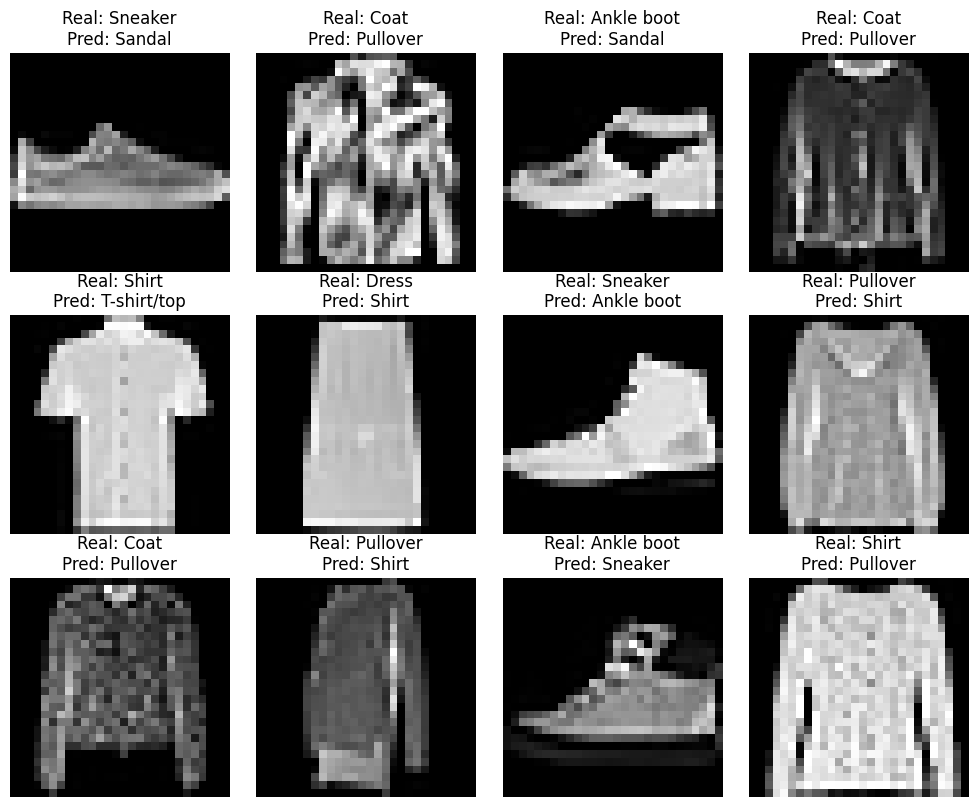

In [ ]:
def denormalize(image):
    # Invierte Normalize, lleva [-1,1] de vuelta a [0,1].
    return image * 0.5 + 0.5

@torch.no_grad()
def show_misclassified(model, data_loader, device, n=12):
    model.eval()
    wrong_images = []
    wrong_labels = []
    wrong_preds = []

    # Recorremos el conjunto hasta juntar n imágenes mal clasificadas
    for images, labels in data_loader:
        logits = model(images.to(device))
        predictions = logits.argmax(dim=1).cpu()

        wrong = predictions != labels

        if wrong.any():
            wrong_images.append(images[wrong])
            wrong_labels.append(labels[wrong])
            wrong_preds.append(predictions[wrong])

        if sum(len(w) for w in wrong_labels) >= n:
            break

    images = torch.cat(wrong_images)[:n]
    labels = torch.cat(wrong_labels)[:n]
    predictions = torch.cat(wrong_preds)[:n]

    ncols = 4
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.7 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, image, true_label, pred_label in zip(axes, images, labels, predictions):
        # Convertimos la imagen a numpy y removemos la dimensión de canal (squeeze)
        img_np = denormalize(image).squeeze().cpu().numpy()
        ax.imshow(img_np, cmap='gray')
        ax.set_title(
            f"Real: {class_names[true_label.item()]}\n"
            f"Pred: {class_names[pred_label.item()]}"
        )
        ax.axis("off")

    for ax in axes[len(images):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_misclassified(model, test_loader, device)

## Ejercicio 16) *Accuracy* por clase

La *accuracy* global puede ocultar diferencias entre categorías.

Para cada clase $k$ calculamos:

$$
\mathrm{accuracy}_k
=
\frac{\mathrm{correctos\ de\ la\ clase}\ k}
{\mathrm{ejemplos\ de\ la\ clase}\ k}.
$$

Esta evaluación se hace sobre el conjunto *test* **después de haber seleccionado el modelo**.

In [ ]:
@torch.no_grad()
def accuracy_per_class(moedel, data_loader, device, n_classes=10):
    model.eval()

    correct =torch.zeros(n_classes, dtype=torch.long)
    total = torch.zeros(n_classes, dtype=torch.long)

    for images, labels in data_loader:
        logits=model(images.to(device))
        predictions =logits.argmax(dim=1).cpu()

        for class_id in range(n_classes):
            mask = labels == class_id

            total[class_id] += mask.sum()
            correct[class_id] += (predictions[mask] == labels[mask]).sum()

    return correct.float() / total.float()

class_acc = accuracy_per_class(model, test_loader, device, n_classes=len(class_names))

for class_id, acc in enumerate(class_acc):
    print(f"{class_names[class_id]:12s}: " f"{acc.item():.3f}")

T-shirt/top : 0.849
Trouser     : 0.970
Pullover    : 0.793
Dress       : 0.894
Coat        : 0.852
Sandal      : 0.944
Shirt       : 0.687
Sneaker     : 0.953
Bag         : 0.971
Ankle boot  : 0.954


### 16.1) Matriz de confusión normalizada

La *accuracy* por clase resume cuántos ejemplos de cada clase fueron clasificados correctamente, pero no muestra **con qué otras clases se confunden los errores**.

Para obtener esa información utilizaremos una **matriz de confusión normalizada**.

Definimos una matriz $C$ de tamaño $10\times10$ donde:

- cada **fila** corresponde a la **clase verdadera**;
- cada **columna** corresponde a la **clase predicha**;
- $C_{ij}$ cuenta cuántos ejemplos cuya clase verdadera es $i$ fueron clasificados como clase $j$.

Por ejemplo:

$$
C_{6,0}
$$

indica cuántas imágenes cuya clase verdadera es `Shirt` fueron clasificadas como `T-shirt/top`.

La diagonal

$$
C_{00},C_{11},\ldots,C_{99}
$$

contiene las clasificaciones correctas.

Para facilitar la comparación entre clases, normalizaremos cada fila:

$$
C^{(\mathrm{norm})}_{ij}
=
\frac{C_{ij}}
{\sum_{k=0}^{9}C_{ik}}.
$$

Entonces cada fila suma aproximadamente 1:

$$
\sum_{j=0}^{9} C^{(\mathrm{norm})}_{ij}=1.
$$

De esta forma, cada elemento puede interpretarse como una **proporción de ejemplos de la clase verdadera $i$ que fueron asignados a la clase $j$**.

En una matriz de confusión normalizada ideal:

- la diagonal tendría valores cercanos a 1;
- los valores fuera de la diagonal serían cercanos a 0.

> **Importante:** esta matriz se calcula sobre `test_loader` porque ya hemos seleccionado la configuración final del modelo usando *validation*.

In [ ]:
@torch.no_grad()
def normalized_confusion_matrix(model, data_loader, device, n_classes=10):
    model.eval()

    confusion = torch.zeros((n_classes, n_classes), dtype=torch.long)

    for images, labels in data_loader:
        images = images.to(device)
        logits = model(images)
        predictions = logits.argmax(dim=1).cpu()

        for true_label, pred_label in zip(labels, predictions):
            confusion[true_label.item(), pred_label.item()] += 1

    #convertimos a float antes de normalizar.
    confusion_normalized = confusion.float()

    #cantidad total de ejemplos de cada clase verdadera
    row_sums = confusion_normalized.sum(dim=1, keepdim=True)

    #Normalizacion por filas.
    confusion_normalized = (confusion_normalized / row_sums)

    return confusion, confusion_normalized

confusion_counts, confusion_normalized = normalized_confusion_matrix(model, test_loader, device, n_classes=len(class_names))

print("Forma:", confusion_normalized.shape)
print("suma de cada fila:", confusion_normalized.sum(dim=1))


Forma: torch.Size([10, 10])
suma de cada fila: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000])


#### Visualización de la matriz

Representaremos la matriz normalizada como una imagen en escala de colores.

Para interpretar el gráfico:

- el eje vertical indica la **clase verdadera**;
- el eje horizontal indica la **clase predicha**;
- los valores de la diagonal representan **clasificaciones correctas**;
- los valores fuera de la diagonal muestran los pares de clases que la red confunde.

Como la matriz está normalizada por filas, los valores se encuentran entre 0 y 1.

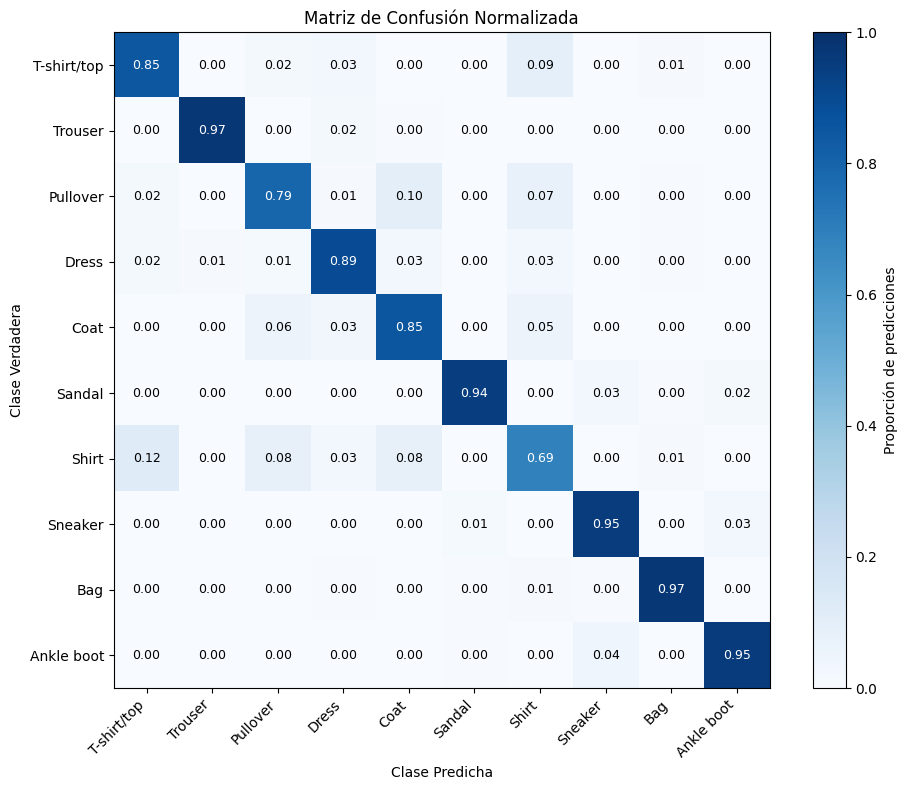

In [ ]:
# Creamos la figura y los ejes
plt.figure(figsize=(10, 8))

# Convertimos a numpy para poder graficar de forma sencilla con matplotlib
matrix_np = confusion_normalized.cpu().numpy()

# Graficamos la matriz como una imagen
im = plt.imshow(matrix_np, cmap="Blues", vmin=0.0, vmax=1.0)

# Agregamos barra de colores
plt.colorbar(im, label="Proporción de predicciones")

# Configuramos etiquetas de los ejes
ticks = np.arange(len(class_names))
labels = [class_names[i] for i in range(len(class_names))]

plt.xticks(ticks, labels, rotation=45, ha="right")
plt.yticks(ticks, labels)

plt.xlabel("Clase Predicha")
plt.ylabel("Clase Verdadera")
plt.title("Matriz de Confusión Normalizada")

# Anotamos los valores numéricos dentro de cada celda
for i in range(matrix_np.shape[0]):
    for j in range(matrix_np.shape[1]):
        color = "white" if matrix_np[i, j] > 0.5 else "black"
        plt.text(
            j, i, f"{matrix_np[i, j]:.2f}",
            ha="center", va="center", color=color, fontsize=9
        )

plt.tight_layout()
plt.show()

#### Cómo interpretar el resultado

La diagonal de la matriz permite observar, clase por clase, qué proporción fue clasificada correctamente.

Por ejemplo, si para una determinada clase aparece:

$$
C^{(\mathrm{norm})}_{ii}=0.91,
$$

significa que aproximadamente el 91 % de los ejemplos de esa clase fueron clasificados correctamente.

Un valor fuera de la diagonal, por ejemplo:

$$
C^{(\mathrm{norm})}_{ij}=0.08,
$$

significa que aproximadamente el 8 % de los ejemplos cuya clase verdadera es $i$ fueron confundidos con la clase $j$.

La matriz de confusión complementa la *accuracy* global porque permite responder preguntas como:

- ¿qué clases son fáciles de reconocer?
- ¿qué clases son más difíciles?
- ¿qué pares de clases se confunden frecuentemente?
- ¿los errores tienen una estructura visual razonable?

En Fashion-MNIST es especialmente interesante observar posibles confusiones entre categorías visualmente semejantes, por ejemplo prendas de la parte superior del cuerpo.

## Ejercicio 17) Preguntas conceptuales

1. ¿Por qué en clasificación necesitamos las etiquetas y en el *autoencoder* no?
2. ¿Qué representa cada uno de los 10 *logits*?
3. ¿Por qué los *logits* no son probabilidades?
4. ¿Qué hace conceptualmente *softmax*?
5. ¿Por qué no agregamos `Softmax` al modelo cuando usamos `CrossEntropyLoss`?
6. ¿Qué recibe `CrossEntropyLoss` como predicción y como *target*?
7. ¿Qué hace `optimizer.zero_grad()`?
8. ¿Qué hace `loss.backward()`?
9. ¿Qué hace `optimizer.step()`?
10. ¿Por qué el bucle `for images, labels in data_loader` recorre *mini-batches*?
11. ¿Por qué evaluamos *train* nuevamente al terminar cada época?
12. ¿Qué diferencia existe entre `model.train()` y `model.eval()`?
13. ¿Qué ocurre con *Dropout* durante evaluación?
14. ¿Qué diferencia conceptual existe entre *loss* y *accuracy*?
15. ¿Por qué *validation* sirve para elegir una configuración y *test* no debería utilizarse para ello?
16. ¿Por qué *SGD* y *Adam* utilizan *learning rates* iniciales diferentes?

## Ejercicio 18) Experimentos sugeridos

Modificar una sola variable por vez ayuda a interpretar el efecto de cada **hiperparámetro**.

### 18.1) Learning rate con SGD

Probar:

```python
SGD_LR = 0.001
SGD_LR = 0.01
SGD_LR = 0.05
```

### 18.2) Dropout

Probar:

```python
DROPOUT_P = 0.0
DROPOUT_P = 0.2
DROPOUT_P = 0.5
```

### 18.3) Número de épocas

Probar:

```python
EPOCHS = 5
EPOCHS = 10
EPOCHS = 20
```

### 18.4) Optimizador

Comparar *SGD* y *Adam* con sus *learning rates* base.

### 18.5) Capacidad de aprendizaje del modelo

Cambiar, por ejemplo, la primera capa oculta:

```text
64 → 64 → 10
128 → 64 → 10
256 → 64 → 10
```

**Regla metodológica:** comparar configuraciones usando *validation* y reservar *test* para la configuración final.